In [1]:
from entire_rxn_with_circuit import *
from hamiltonians import *
from one_ham_with_ckt import *
import linlin_energy_check as echk

In [2]:
import numpy as np
if not hasattr(np, "ComplexWarning"):
    np.ComplexWarning = np.exceptions.ComplexWarning
for _old, _new in (("string_", "bytes_"), ("unicode_", "str_"),
                   ("float_", "float64"), ("complex_", "complex128")):
    if not hasattr(np, _old):
        setattr(np, _old, getattr(np, _new))

In [4]:
from pathlib import Path
frames = load_xyz_trajectory(Path("H3_rxn_trj.xyz"))
geom = frames[0:3]                     

In [33]:
pairs = [(i, j) for orbs in ([0,1,2], [3,4,5])
         for n, i in enumerate(orbs) for j in orbs[n + 1:]]
weights = [1.0] * len(pairs)

In [14]:
h_idx_list = []
E_init_list = []
E_final_list = []
E_ref_list = []
err_list = []
circuits_by_geometry = []
resources_by_geometry = []

for h_idx, geom in enumerate(frames[0:2]):
    Ham = linlin.HamiltonianBuilder().build_molecule(
        geometry = geom, 
        basis="sto-3g",
        multiplicity=2,
        charge=0,
        active_indices=None,
        ancilla_index=0,
        n_active_electrons=None,
        n_active_orbitals=None,
        use_casscf_orbitals=True,
        max_dense_qubits=12,
        use_procrustes_gauge=False,
        align_reference=None,
        fix_spin_ss=None,
        compute_dense=False,
        spectral_width_method="sparse",
    )
    filter_terms =  SquareWaveFilter().get_coefficients(L=2*Ham.spectral_width,K=400,tau=0.1,A=1.0,window="lanczos",p=1, drop_zeros=False,eps=1e-15, sign=+1)
    n_system = int(Ham.n_system)
    pairs, weights = make_pairs_and_weights(n_system, conserve_spin=False, spin_adapted=True)
    W_list, resources = build_W_circuits_only(
    system_qubits=Ham.system_qubits,
    H_int=Ham.interaction,
    anc=Ham.ancilla,
    tau=filter_terms["tau"],
    filter_terms=filter_terms["filter_terms"],
    T_filter=filter_terms["T_filter"],
    pairs=pairs,
    weights=weights,
    N_applications=100,
    reps_per_W=200,
    trotter_steps_H=2,
    rng_seed=123,
    final_rank=4,
    keep_circuits="all",
)
    H_sparse = echk.system_hamiltonian_sparse(Ham.qubit, n_system)
    
    ref_E = echk.reference_energies(Ham.qubit, n_system, n_electrons=3, Na=1, Nb=2, H_sparse=H_sparse)
    seq = [r["pair"] for r in resources] #pair_sequence_from_resources(None, pairs, weights, 200, 123)
    
    chain = echk.run_W_chain_energies(
                ancilla=Ham.ancilla, 
                system_qubits=Ham.system_qubits,
                H_int=Ham.interaction, 
                qubit_ham=Ham.qubit, 
                n_system=n_system,
                tau=filter_terms["tau"], 
                filter_terms=filter_terms["filter_terms"], 
                T_filter=filter_terms["T_filter"],
                pair_sequence=seq,
                rho_init=None,                 # None on geometry 0
                occ_spin_orbs=[0,1,2], 
                reps_per_W=200,
                trotter_steps_H=2,
                final_rank=4, 
                H_sparse=H_sparse,
            )
    rho_carry = chain["rho_final"]
    err = abs(chain["final_energy"] - ref_E["E_fixed_N"])
    E_init = chain["initial_energy"]
    E_final = chain["final_energy"]
    E_ref = ref_E["E_fixed_N"]

    err = abs(E_final - E_ref)
    err_mHa = err * 1000

    h_idx_list.append(h_idx)
    E_init_list.append(E_init)
    E_final_list.append(E_final)
    E_ref_list.append(E_ref)
    err_list.append(err_mHa)
    circuits_by_geometry.append(W_list)
    resources_by_geometry.append(resources)
    #print(err)
#print(seq)
    

[spectral] width=2.614612 via Lanczos in 0.1 s (no dense matrix)
[trotter] propagator built once in 0.0 s (262 moments); reused for all 100 W blocks
[filter] 401 active terms -> 802 propagator insertions per W
[W sampling] 100 applications -> 6 unique sampled jump-pair circuits
[unique W 1/6] 215350 moments, 555000 ops, 6.2 s
[unique W 2/6] 215350 moments, 555000 ops, 5.8 s
[unique W 3/6] 214546 moments, 555000 ops, 6.1 s
[unique W 4/6] 215350 moments, 555000 ops, 5.1 s
[unique W 5/6] 215350 moments, 555000 ops, 7.9 s
[unique W 6/6] 214546 moments, 555000 ops, 5.5 s
[geometry total] width=7 depth=21513292 ops=55500000
[sim] 100 applications -> 6 unique W channels to build
[sim] unique W 1/6  completeness=2.39e-12  12.2 s
[sim] unique W 2/6  completeness=2.39e-12  14.2 s
[sim] unique W 3/6  completeness=2.32e-12  20.1 s
[sim] unique W 4/6  completeness=2.58e-12  19.1 s
[sim] unique W 5/6  completeness=2.43e-12  17.1 s
[sim] unique W 6/6  completeness=2.37e-12  19.4 s
[spectral] width=2.

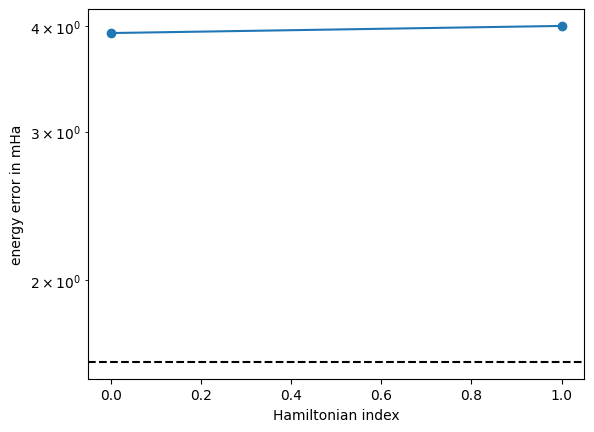

In [15]:
import matplotlib.pyplot as plt

plt.plot(h_idx_list, err_list, "o-")
plt.yscale("log")
plt.axhline(1.6, linestyle="--", color="black")
plt.xlabel("Hamiltonian index")
plt.ylabel("energy error in mHa")
plt.show()

In [16]:
err_list

[3.9248751049201225, 4.001965446802869]